# Data and context

**Part 1 of 4** · Next: [Exploration and gold layer](02_exploration_and_gold_layer.ipynb) ·
Then: [Baselines and model](03_baselines_and_model.ipynb) · [Results](04_results.ipynb)

What Backblaze publishes, the question we ask of it, and how three years of daily drive records become clean
tables on one laptop: the fleet and its failures, the S.M.A.R.T. attributes, the tools, and the first two data
layers, bronze (a faithful copy) and silver (hard drives only, split into drive lives).

In [1]:
from backblaze_hdd_failure_prediction.figures import use_style
from backblaze_hdd_failure_prediction.notebooks import data_and_context as nb

use_style()
con = nb.connect()  # DuckDB, with the catalog of drive models loaded

## 1 · Backblaze and the question

Backblaze, a cloud storage company, has published one row per drive and day since 2013: date, serial number,
model, capacity, a `failure` flag, location and S.M.A.R.T. attributes. It is the largest public record of real
drive failures. A **failure** (`failure = 1`) marks the day Backblaze removed a drive that stopped working or
showed signs of failing soon.

We take 12 quarters, Jul 2023 – Jun 2026, and count drives, **drive-days** (one drive on one day) and failures
from a small table per model name and quarter, joined with our model catalog to leave **SSDs out**. The
**annualised failure rate** (AFR) is failures ÷ (drive-days ÷ 365).

In [2]:
quarters = nb.fleet_by_quarter(con)
nb.show_window(con, quarters)

Window: 2023-07-01 to 2026-06-30, 1,096 days, 12 quarters
Hard drives: 406,098, of which 163,485 (40.3 %) first seen after 2023-07-01
Hard-drive drive-days: 330,072,154; failures: 13,531
AFR: 1.50 % a year; one failure every 24,394 drive-days


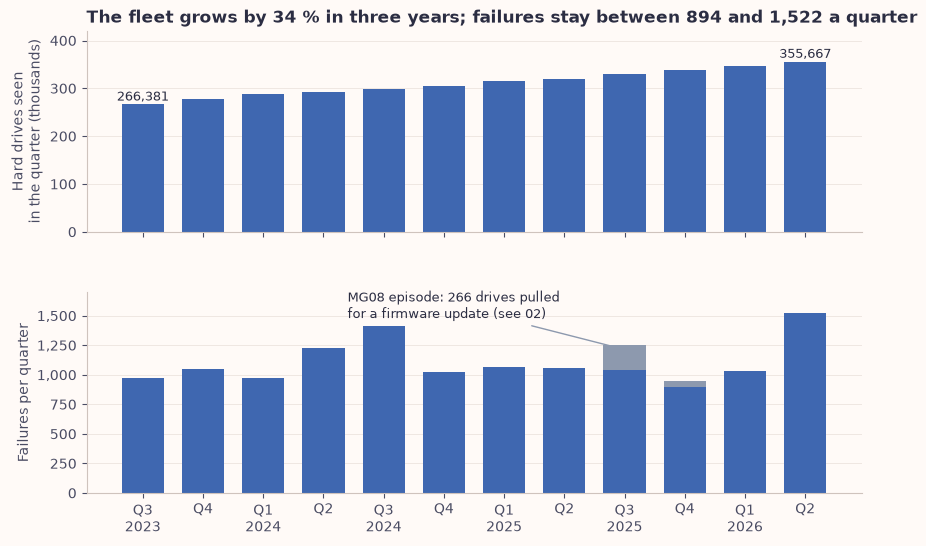

In [3]:
nb.plot_fleet_and_failures(quarters)

**What we see**

- The fleet grows from 266,381 to 355,667 hard drives a quarter, and 163,485 of the 406,098 hard drives
  (40.3 %) arrive during the window.
- 13,531 failures. The grey block is the MG08 episode: 266 Toshiba MG08ACA16TEY drives pulled for a firmware
  update, not broken (02).
- Failures are rare: 1.50 % a year, one every 24,394 drive-days. Always answering "no" is right on more than
  99.99 % of drive-days, so accuracy says nothing here (03).

In [4]:
overall = nb.show_rates_by_manufacturer(con)

,drive_days,failures,AFR (%)
manufacturer,,,
HGST,"36,006,276","2,668",2.70
Seagate,"120,946,852","6,015",1.82
Toshiba,"105,807,685","3,615",1.25
WDC,"67,311,341","1,233",0.67


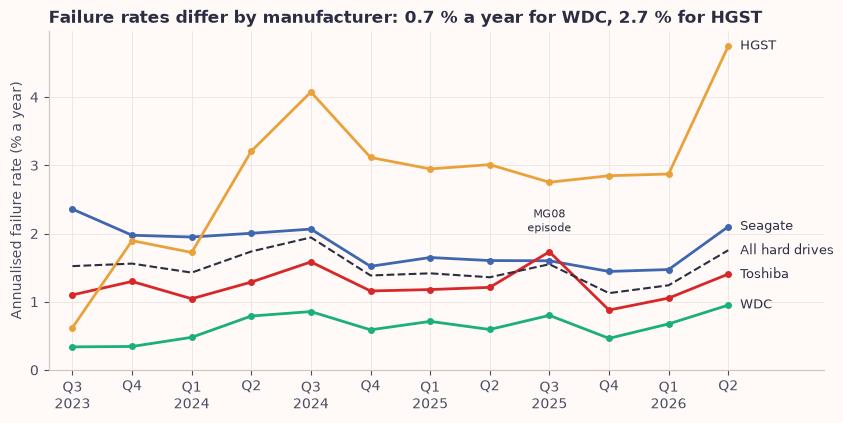

Whole fleet, per quarter: 1.13 % to 1.94 % a year


In [5]:
nb.plot_failure_rate_by_manufacturer(con, quarters, overall)
nb.show_fleet_rate_range(quarters)

**What we see**

- HGST drives fail at 2.70 % a year, Seagate at 1.82 %, Toshiba at 1.25 % and WDC at 0.67 %: the manufacturer
  and the drive model carry information, and both become variables (02).
- The whole fleet moves between 1.13 % and 1.94 % a year from one quarter to the next.

### The question

> **Decision:** for every hard drive and day, predict the probability that it fails in the next 15 days (the
> **horizon**, H = 15, chosen from the data in 02). **Why:** it is the technician's daily decision, which drives
> to back up or replace now; "will it fail?" has no answer without a horizon. **Discarded as the main
> question:** fleet-level ones (how many drives will fail; how likely a model of a given age is to fail), which
> calibrated per-drive probabilities can answer later.

## 2 · S.M.A.R.T. attributes

S.M.A.R.T. (Self-Monitoring, Analysis and Reporting Technology) is a set of counters each drive keeps about
itself. Each attribute has a **raw** value, the counter itself (hours, °C, sectors), and a **normalised** value,
a health score on a scale each manufacturer sets and does not publish. The same 33–35 °C (attribute 194,
temperature) gave these normalised values on 30 Jun 2025:

| HGST | Seagate | Toshiba | WDC |
|---|---|---|---|
| 171 | 33 | 100 | 59 |

The **rule of five**, what a technician checks today, alerts when one of five raw counters is above 0 (or rose
recently, 03). In Backblaze's 2016 analysis, 76.7 % of failed drives had one of them above 0, against 4.2 % of
healthy drives.

| Attribute | Name | What it counts |
|---|---|---|
| 5 | Reallocated sectors | bad sectors replaced by spare ones |
| 187 | Reported uncorrectable errors | read errors the drive could not correct |
| 188 | Command timeouts | operations aborted because the drive did not answer in time |
| 197 | Current pending sectors | unstable sectors waiting to be reallocated |
| 198 | Offline uncorrectable sectors | sectors found unreadable in the drive's own scan |

Not every manufacturer reports every attribute (02). Who makes the fleet's drives?

In [6]:
nb.show_last_quarter(con, quarters)

Hard drives seen in Q2 2026


,drives,drive_models,share (%)
manufacturer,,,
Toshiba,"125,382",12,35.3
Seagate,"113,116",30,31.8
WDC,"91,461",9,25.7
HGST,"25,708",7,7.2


**What we see**

- In the last quarter Toshiba runs 35.3 % of the hard drives, Seagate 31.8 %, WDC 25.7 % and HGST 7.2 %.
- 187 and 188 come almost only from Seagate drives (02): for two thirds of the fleet the rule of five rests on
  three counters. An attribute that is not reported stays empty, never 0 (0 means "no errors").
- Raw counters share their units across manufacturers; normalised values do not. We use raw values (02 gives
  the exceptions).

## 3 · Tools

One laptop with about 3 GB of free RAM: memory shaped the code.

> **Decision:** DuckDB on Parquet files, not PySpark. **Why:** one machine, not a cluster; PySpark needs Java,
> outside the uv environment; DuckDB runs SQL on Parquet files and spills to disk when a query does not fit in
> memory. Parquet is stored by column, so each step reads only the columns it needs.

> **Decision:** everything local, one uv environment with pinned versions. **Why:** isolation and
> reproducibility.

> **Decision:** heavy steps run as modules in `src/`, one quarter per process and one day at a time, under a
> 2 GB memory cap. **Why:** one pass over a whole layer once ran the machine out of memory.

In [7]:
nb.show_versions()

Python 3.14.8
duckdb     1.5.6
lightgbm   4.7.0
pandas     3.1.1
matplotlib 3.11.2
streamlit  1.66.1
DuckDB memory limit: 2GB; beyond it, temporary files go to data/duckdb_tmp/


**What we see**

- `uv.lock` pins these versions and every indirect dependency.
- DuckDB's own limit is not enough (a process can use more memory than DuckDB counts), so heavy steps are also
  capped from outside (`systemd-run` with `MemoryMax=2G`).

## 4 · Bronze and silver

Three layers of Parquet files, one file per day, each built from the previous one by a module.

> **Decision (bronze):** a faithful copy of the CSVs: every row (SSDs too) and column, as text, nothing
> filtered. **Why:** no irreversible decision before seeing the data.

> **Decision:** Parquet without dictionary encoding. **Why:** about 4 s per day instead of about 25 s (2 h
> instead of 8 h in all), for files about 25 % larger.

> **Decision (silver):** hard drives only, typed, with a unified drive model, the manufacturer, a boot-drive
> flag and the drive's **life** (section 5). Checked every day: typed values convert back to the original text,
> and kept + SSD + dropped rows = bronze rows.

In [8]:
nb.show_layers(con)

Bronze: 333,732,420 rows in 1,096 days
Silver drops 3,660,266 SSD rows and 501 rows reported after a failure
bronze    333,732,420 rows    12 GB   every CSV row and column, as text
silver    330,071,653 rows   9.2 GB   hard drives only, types, drive model, manufacturer, boot drive, life
gold      330,071,653 rows    17 GB   the same rows, plus the label and 131 variables (02)


In [9]:
nb.show_catalog(con)

,original_names,drive_models,boot_drives
media,,,
HDD,76,74,9
SSD,22,22,0


,original_name,drive_model
0,Hitachi HDS5C4040ALE630,HGST HDS5C4040ALE630
1,WUH721816ALE6L4,WDC WUH721816ALE6L4


**What we see**

- Bronze holds 333,732,420 rows. Silver drops 3,660,266 SSD rows and 501 rows reported after a failure while
  the drive was still in its slot, and keeps 330,071,653.
- 98 original model names: 22 SSDs and 76 hard-drive names, which make 74 drive models once two drives spelled
  two ways are unified. 9 are boot drives (they hold a server's operating system): kept and flagged.
- Gold (02) keeps the same rows and adds the label and the variables.

## 5 · Drive lives

A failure should be a drive's last day, yet some hard drives appear again after one. A small table built from
bronze lists them, with how long each was absent and where it came back.

,drives,same_pod,same_slot,median_days_seen_after
back within 7 days,167,100.0%,100.0%,2
back after 7 days,151,6.6%,0.0%,369


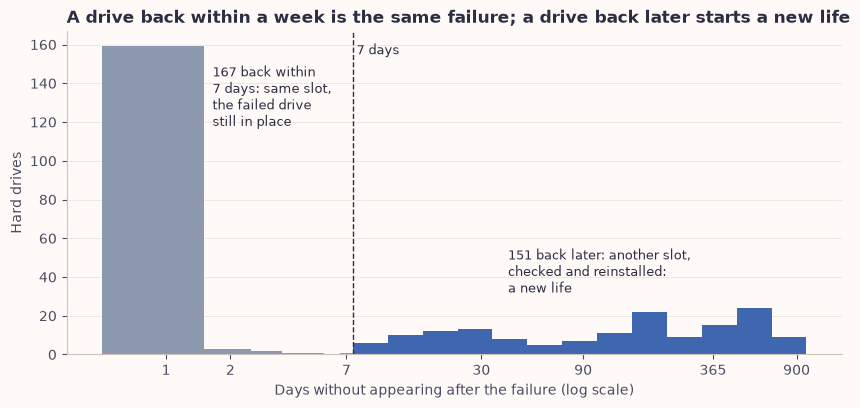

In [10]:
nb.show_reappearing_drives(con)

**What we see**

- 318 hard drives appear again after a failure. 167 come back within 7 days, always in the same slot, for about
  2 days: the failed drive had not been removed yet.
- 151 come back later, never in the same slot and mostly in another pod (storage server), and keep reporting for
  about a year: they were checked and reinstalled.

> **Decision:** a drive back after more than 7 days without appearing starts a new **life**; the tail (the rows
> within those 7 days) is dropped. Each life ends in at most one failure, the event we predict. **Why:** the
> tail repeats a failure already counted; a reinstalled drive is real fleet data, and "it failed before" may be
> a strong signal. **Discarded:** keeping only each drive's first failure.

In [11]:
nb.show_lives(con, quarters)

,drives,failures,mg08_episode
life,,,
1,"406,098","13,498",255
2,154,32,11
3,1,0,0


All later lives: 32 of 155 fail (20.6 %), 11 in the MG08 episode
Later lives outside the MG08 episode: 21 of 144 fail (14.6 %), median 519 days in service
Annualised: 11.7 % a year, against 1.50 % for the fleet (7.8 times)


**What we see**

- 406,253 lives: 406,098 first lives, 154 second and 1 third; 13,530 end in a failure.
- 32 of the 155 later lives fail (20.6 %), but 11 of those are MG08 pulls. Without them, 21 of 144 fail
  (14.6 %) in a median of 519 days: 11.7 % a year, 7.8 times the fleet's 1.50 %. So `life` becomes a variable (02).

## Takeaways

- 330 million hard-drive drive-days and 13,531 failures in three years: one every 24,394 drive-days.
- The question is per drive, with a horizon: the probability that this drive fails within 15 days.
- Raw S.M.A.R.T. counters share units across manufacturers; normalised values do not; not every manufacturer
  reports every attribute.
- DuckDB and Parquet on one laptop, heavy steps by quarter and by day under a 2 GB memory cap.
- Bronze keeps everything as text; silver keeps the hard drives, typed and split into lives.

**Next, notebook 02:** which attributes each manufacturer reports, how early the signal appears (why H = 15),
the MG08 episode, and the gold layer.